# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 1: Reconstrucción de una imagen

**Grupo:** 7

**Integrantes:**
- Agustín Pérez
- Cristóbal Robinson
- Vicente Pardo
- Sofía Solorza


## Configuración
### Librerias

In [210]:
# Se importan librerias permitidas para resolver el problema
import numpy as np
import matplotlib.pyplot as plt

# usamos esta libreria para guardar las imagenes generadas en el notebook
import os

### Carga de datos

In [211]:
# Se usa la forma que se muestra en el enunciado
datos = np.load("datos_P1.npz")

matriz_a = datos["A"]
vector_b = datos["b"]

In [212]:
# Funcion para guardar las imagenes generadas en el notebook

# antes se crea la carpeta donde se guardaran las imagenes generadas en el notebook
os.makedirs("resultados", exist_ok=True)

def guardar_imagen(imagen, titulo, nombre_archivo):
    plt.figure(figsize=(6, 6))
    plt.imshow(imagen.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    plt.title(titulo)
    plt.axis("off")
    # Guardamos la imagen en la carpeta
    plt.savefig(os.path.join("resultados", nombre_archivo), bbox_inches="tight", dpi=200)
    plt.close()

## (a) Mínimos Cuadrados

## (b) Reconstrucción

### b.i.- Implementación

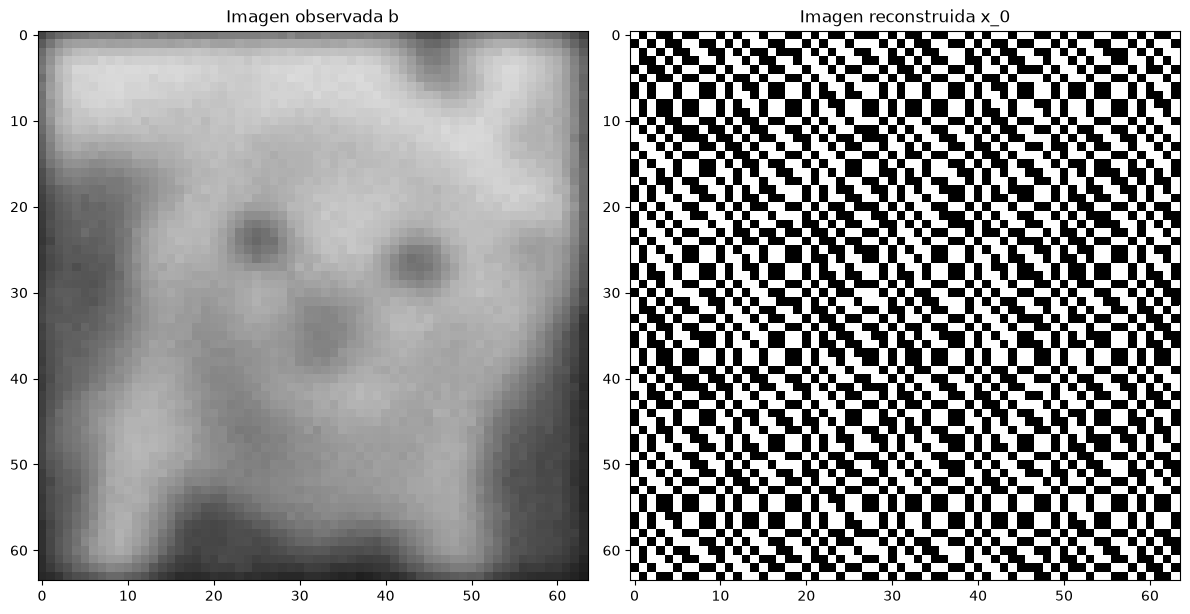

In [213]:
# Calculamos x_0, para esto resolvemos el sistema lineal
# En el enunciado se menciona que se puede utilizar np.linalg.solve
x_0 = np.linalg.solve(matriz_a, vector_b)

# Comparamos la reconstrucción con la imagen observada
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(vector_b.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Imagen observada b")
ax[1].imshow(x_0.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Imagen reconstruida x_0")
plt.tight_layout()
plt.show()

# Guardamos cada figura por separado
guardar_imagen(vector_b, "Imagen observada b", "imagen_observada_b.png")
guardar_imagen(x_0, "Imagen reconstruida x_0", "imagen_reconstruida_x0.png")


### Calculamos la norma, max y el residuo

In [214]:
# norma euclidiana
norma_euclidiana_x0 = np.linalg.norm(x_0)

# maximo absoluto de x_0
max_x0 = np.max(np.abs(x_0))

# residuo, para este vamos a calcular la matriz A por x_0
# por lo que vi si se puede usar "@" para multiplicar matrices
residuo = np.linalg.norm(matriz_a @ x_0 - vector_b)

### Revisamos los resultados

In [215]:
print(f"Norma euclidiana de x_0: {norma_euclidiana_x0}")
print(f"Maximo absoluto de x_0: {max_x0}")
print(f"Residuo: {residuo}")

Norma euclidiana de x_0: 992626.416729
Maximo absoluto de x_0: 55257.75733986092
Residuo: 1.5111379587256674e-11


### b.i.- Respuestas

- ¿$x_0$ se parece a $b$?
  No, mientras que $b$ muestra la imagen algo borrosa pero entendible, en $x_0$ solo muestra los pixeles blancos y negros sin alguna forma reconocible. Esto ocurre porque sus valores estan fuera de $[0, 1]$ y al graficar con vmin = 0 y vmax = 1, el resto de la informacion se pierde

- ¿Se parece a una imagen?
  No, como se menciono antes, solo se puede ver los pixeles sin forma, como ruido. Ademas, no podria ser interpretada como una imagen, ya que una imagen tiene pixeles en $[0, 1]$, y como la norma tiene que ser a lo mas $\sqrt{n} = 64$ y su maximo es a lo mas $1$, mientras que $\|x_0\|_2 \approx 992626$ y $\max_i |x_{0,i}| \approx 55258$ valores mucho mayores a los esperados.

- Residuo.
  $\|Ax_0-b\|_2 \approx 1.5\cdot 10^{-11}$, es decir, $x_0$ resuelve $Ax=b$ casi de forma exacta. Sin embargo, como $b=Ax^*+\eta$, al  ajustar $b$ exactamente $x_0$ tambien reproduce el ruido $\eta$. Por lo que un residuo pequeño no implica una buena reconstrucción.
  

### b.ii.- Explicación

## (c) Regularización de Tikhonov (método ridge)

### c.iv.- Implementación
### Primero creamos los elementos basicos

In [216]:
# Calculamos la matriz A^tA
AtA = matriz_a.T @ matriz_a

# Calculamos el vector A^tb
Atb = matriz_a.T @ vector_b

# Y la matriz identidad
n = matriz_a.shape[0] 
matriz_identidad = np.eye(n)

### Calculo de las reconstrucciones

In [217]:
# Creamos la matriz del sistema para cada lambda y resolvemos
# Usamos una lista lambda para guardar los valores de lambda que se van a probar
lista_lambda = [10**-3.5, 10**-2.5, 1]
lista_lambda_strings = ["10^-3.5", "10^-2.5", "1"] # para que el print sea mas entendible

resultados = []
for valor_lambda, lambda_string in zip(lista_lambda, lista_lambda_strings):
    matriz_sistema = AtA + valor_lambda * matriz_identidad
    solucion = np.linalg.solve(matriz_sistema, Atb)

    # Calculamos la norma de x_lambda
    norma_x_lambda = np.linalg.norm(solucion)
    # y su residuo
    residuo_x_lambda = np.linalg.norm(matriz_a @ solucion - vector_b)

    # Mostramos los resultados
    print(f"Resultados para lambda = {lambda_string}:")
    print(f"Norma de x_lambda: {norma_x_lambda}")
    print(f"Residuo de x_lambda: {residuo_x_lambda} (delta: 0.64)") # Enunciado pide comparar con delta = 0.64
    print()

    # y por ultimo guardamos la reconstrucción para mostrarla
    resultados.append(solucion)


Resultados para lambda = 10^-3.5:
Norma de x_lambda: 41.135990957686076
Residuo de x_lambda: 0.5545587811349489 (delta: 0.64)

Resultados para lambda = 10^-2.5:
Norma de x_lambda: 40.17481845801241
Residuo de x_lambda: 0.6125143500730488 (delta: 0.64)

Resultados para lambda = 1:
Norma de x_lambda: 19.3344726724977
Residuo de x_lambda: 19.975280603910214 (delta: 0.64)



### Reconstrucción con regularización de Tikhonov

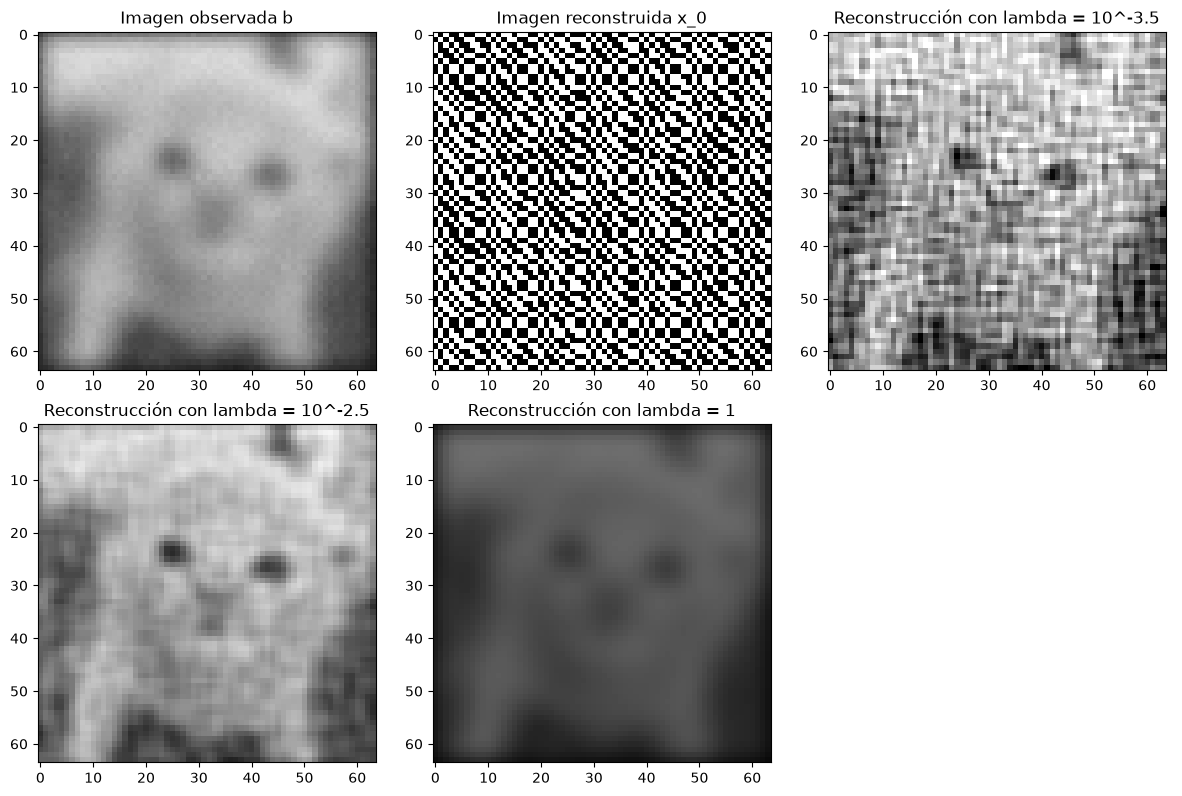

In [218]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.flatten()  # Aplanamos el arreglo de ejes para poder indexarlos facilmente

ax[0].imshow(vector_b.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Imagen observada b")
ax[1].imshow(x_0.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Imagen reconstruida x_0")

# Ahora mostramos las reconstrucciones para cada lambda
ax[2].imshow(resultados[0].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[2].set_title(f"Reconstrucción con lambda = {lista_lambda_strings[0]}")
ax[3].imshow(resultados[1].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[3].set_title(f"Reconstrucción con lambda = {lista_lambda_strings[1]}")
ax[4].imshow(resultados[2].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[4].set_title(f"Reconstrucción con lambda = {lista_lambda_strings[2]}")
ax[5].axis('off')  # Ocultamos el ultimo ya que no tiene imagen

plt.tight_layout()
plt.show()


# Ahora guardamos para cada una de las reconstrucciones con lambda
guardar_imagen(resultados[0], f"Reconstrucción con lambda = {lista_lambda_strings[0]}", "reconstruccion_lambda_-3.5.png")
guardar_imagen(resultados[1], f"Reconstrucción con lambda = {lista_lambda_strings[1]}", "reconstruccion_lambda_-2.5.png")
guardar_imagen(resultados[2], f"Reconstrucción con lambda = {lista_lambda_strings[2]}", "reconstruccion_lambda_1.png")



## (d) Píxeles dañados


Norma de x_lambda con b_def: 48.6911168401266
Residuo de x_lambda con b_def: 10.084028267435565


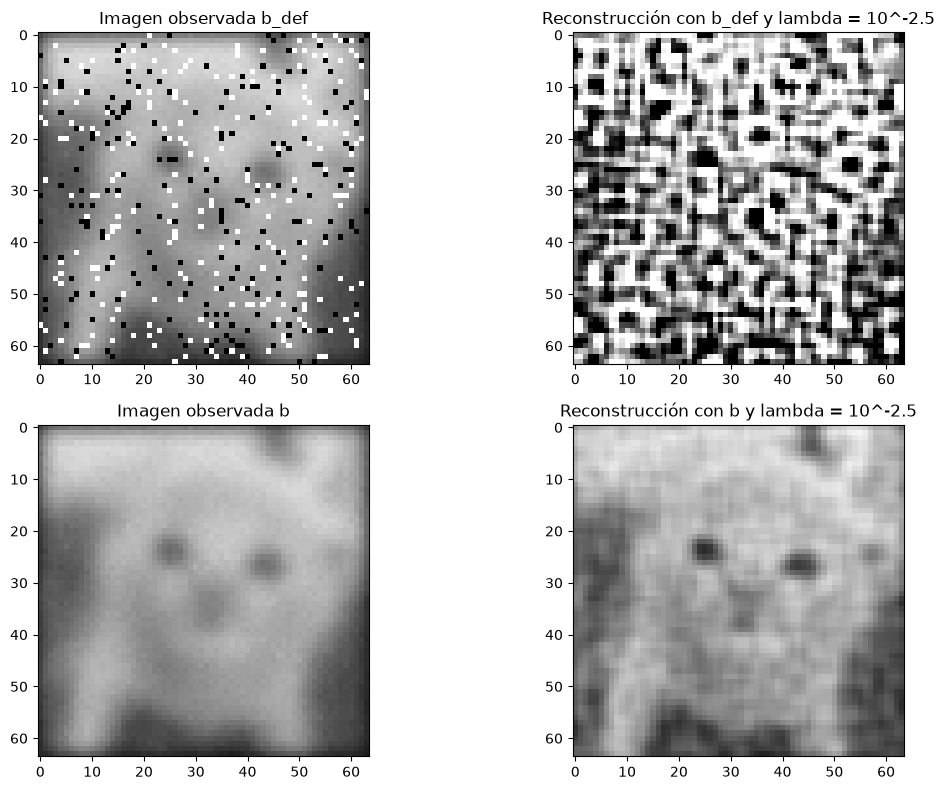

In [219]:
vector_b_def = datos["b_def"]

# Hacemos el mismo procedimiento que antes pero ahora con b_def
Atb_def = matriz_a.T @ vector_b_def

# El enunciado nos pide para 10^-2.5
matriz_sistema_def = AtA + (10**-2.5) * matriz_identidad
solucion_def = np.linalg.solve(matriz_sistema_def, Atb_def)

norma_def = np.linalg.norm(solucion_def)
residuo_def = np.linalg.norm(matriz_a @ solucion_def - vector_b_def)

print(f"Norma de x_lambda con b_def: {norma_def}")
print(f"Residuo de x_lambda con b_def: {residuo_def}")

# Por ultimo mostramos la reconstrucción con b_def, comparamos con la imagen observada y la reconstrucción con lambda = 10^-2.5
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].imshow(vector_b_def.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[0, 0].set_title("Imagen observada b_def")
ax[0, 1].imshow(solucion_def.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[0, 1].set_title("Reconstrucción con b_def y lambda = 10^-2.5")
ax[1, 0].imshow(vector_b.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[1, 0].set_title("Imagen observada b")
ax[1, 1].imshow(resultados[1].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[1, 1].set_title("Reconstrucción con b y lambda = 10^-2.5")

plt.tight_layout()
plt.show()

# Volvemos a guardar las imágenes generadas por separado
guardar_imagen(vector_b_def, "Imagen observada b_def", "imagen_observada_b_def.png")
guardar_imagen(solucion_def, "Reconstrucción con b_def y lambda = 10^-2.5", "reconstruccion_b_def.png")

### d.ii.- $\|\tilde{b} - b\|_2$

In [220]:
norma_diferencia_b = np.linalg.norm(vector_b_def - vector_b)
print(f"Resultado ||b_def - b||_2 : {norma_diferencia_b}")


Resultado ||b_def - b||_2 : 10.884961772516812


## (Bonus)
Por la (d) i, el ruido de la observación con píxeles dañados es $\tilde{\eta} = \eta + (\tilde{b} - b)$, donde $\eta$ es el ruido del sensor y $\tilde{b} - b$ es el aporte de los píxeles dañados. Como cerca del 10% de los píxeles están dañados, el vector $\tilde{b} - b$ debería ser distinto de cero solo en esas posiciones. Por lo tanto, usamos $\tilde{b} - b$ para identificar los píxeles dañados y construir $w$

In [221]:
# Comprobamos
diferencia_pixeles = vector_b_def - vector_b
total_pixeles = 0
for i in range(len(vector_b)):
    if diferencia_pixeles[i] != 0:
        total_pixeles += 1
print(f"Total de pixeles dañados: {total_pixeles}")


Total de pixeles dañados: 430


In [222]:
vector_w = (diferencia_pixeles == 0).astype(int)  # 0 si el pixel esta dañado, 1 si no

print(np.sum(vector_w))  # Total de pixeles no dañados

3666


### Proceso
Como $W$ es diagonal,
$$(Ax-\tilde{b})^T W (Ax-\tilde{b}) = \sum_{p=1}^n w_p\big((Ax)_p - \tilde{b}_p\big)^2 ,$$
asi que los pixeles con $w = 0$ no aparecen en la suma y por lo tanto la reconstruccion no se ve afectada por ellos. 

Siguiendo el mismo procedimiento de (a) i, con $r(x) = Ax - \tilde{b}$ y $q_W(u) = u^T W u$, se obtiene $Dq_W(u) = 2u^T W$ y por la regla de la cadena y $W^T = W$,
$$\nabla J_W(x) = 2A^T W (Ax - \tilde{b}) + 2\lambda x$$
Igualando a cero y reordenando, se obtiene
$$(A^T W A + \lambda I)\,x = A^T W \tilde{b} ,$$

y buscamos la solucion de este sistema porque minimiza $J_W(x)$, que seria la mejor imagen reconstruida sin los pixeles dañados.

In [223]:
matriz_w = np.diag(vector_w)
AtWA = matriz_a.T @ matriz_w @ matriz_a

# Usamos el valor de lambda que aparece en el enunciado para la d
matriz_sistema_bonus = AtWA + (10**-2.5) * matriz_identidad

vector_b_bonus = matriz_a.T @ matriz_w @ vector_b_def

# Resolvemos el sistema
solucion_bonus = np.linalg.solve(matriz_sistema_bonus, vector_b_bonus)

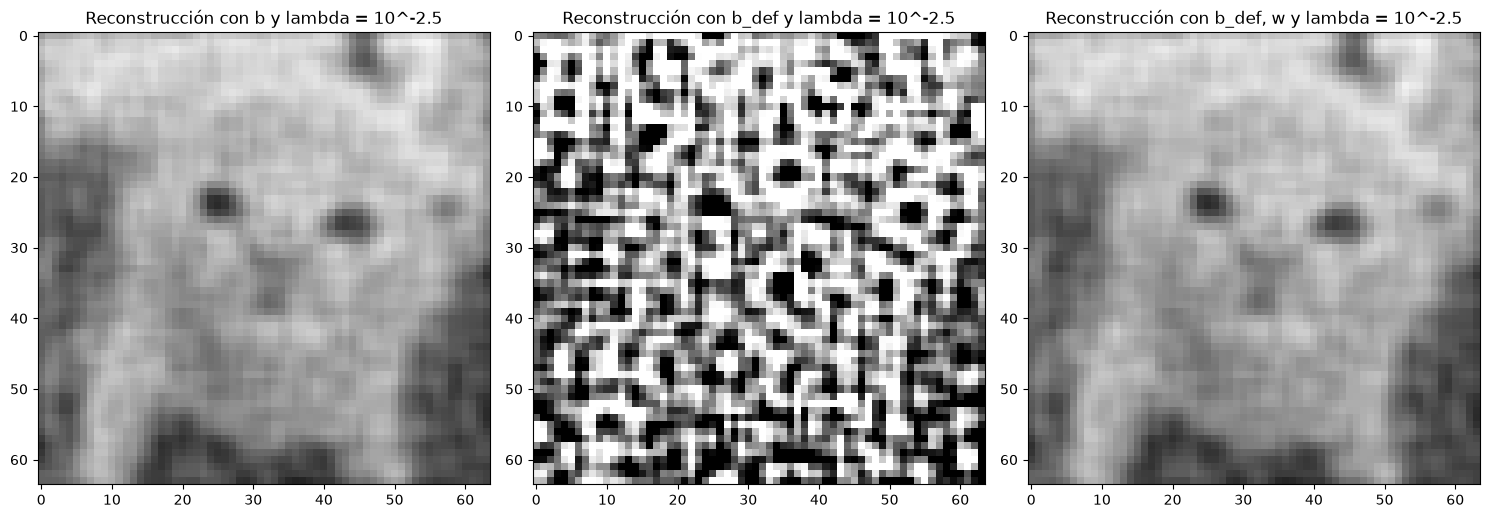

In [224]:
# Graficamos y comparamos con la reconstrucción con b, b_def y lambda = 10^-2.5
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(resultados[1].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Reconstrucción con b y lambda = 10^-2.5")
ax[1].imshow(solucion_def.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Reconstrucción con b_def y lambda = 10^-2.5")
ax[2].imshow(solucion_bonus.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Reconstrucción con b_def, w y lambda = 10^-2.5")
plt.tight_layout()
plt.show()

# Guardamos las imágenes generadas por separado
guardar_imagen(solucion_bonus, "Reconstrucción con b_def, w y lambda = 10^-2.5", "reconstruccion_b_def_bonus.png")

In [225]:
# Revisamos el residuo solo con los pixeles no dañados
residuo_bonus =np.linalg.norm(vector_w * (matriz_a @ solucion_bonus - vector_b_def))
print(f"Residuo: {residuo_bonus}")

Residuo: 0.5798508458103471
